# The slack node's value to VPLs, from the pgm and the DF objective (experiment 3)

Same figures as `v5/09_VPL_siting_parity(_from_pgm)`, once per grid pair. All are the two-stage procedure at
Gamma = 10, 4 days:

| series | runs |
|---|---|
| VPL at VPL | exp2, VPL in both stages (slack allowed) |
| VPL w/o slack | exp3 `no_slack`: VPL, `not_candidate_set=[source]` in both stages |
| VPL at CESS+slack | exp3 `cess_plus_slack`: stage 1 CESS, stage 2 VPL on the CESS sites + every slack |
| CESS (reference) | exp2, CESS in both stages |

parity = (worst - obj) / (worst - obj_CESS), worst = no storage (exp3's baseline of that grid pair), applied per
objective column (`pgm_objective`, and the DF `objective`), both on the term `OBJECTIVE_TERM` picks:
`"total"` (the full objective, `w_current * sum(ell)` included) or `"congestion"` (that term alone). Not clipped: a VPL
can beat CESS. `PLOT_OBJECTIVE` ("model" / "pgm" / "both") picks the columns; under "both" colour/marker is the
series and **linestyle** the objective (solid = pgm, dashed = model).

In [1]:
print("Cell Started")
from IPython.display import clear_output, display

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd().parent))   # paper_companion/: vpl_results.py, shared by every experiment
import vpl_results as vr   # the run reader for slurm_jobs/DF_wc003_experiments/

print("Cell Finished")
clear_output()
pd.set_option("display.width", 250)

In [2]:
#USED_GRIDS = ["C0S0", "S0R0", "R0C0"]   # only these grid pairs are loaded, tabled and plotted
USED_GRIDS = ["C0S0"]   # only these grid pairs are loaded, tabled and plotted

GRIDS = vr.grid_pairs(USED_GRIDS)           # as the "grids" column spells them ("C0,S0", ...)

# Where the sweep folders (as the scripts wrote them, job_<id>/ subfolders and all) were copied.
RESULTS = Path(r"C:\Users\VerdaasdonkF\OneDrive - University of Twente\Desktop\results\v5_reweighted_261022")
EXP1 = RESULTS / "DF_exp1_two_stage_validation" / "DF_exp1_two_stage_validation"
EXP2 = RESULTS / "DF_exp2_vpl_vs_cess" / "DF_exp2_vpl_vs_cess"
EXP3 = RESULTS / "DF_exp3_slack_value" / "DF_exp3_slack_value"                     # + one baseline per grid pair

# which objective the curves show: "pgm" (AC re-pricing), "model" (DF, as solved) or "both"
PLOT_OBJECTIVE = "both"
OBJECTIVES = vr.objective_columns(PLOT_OBJECTIVE)

# which term: "total" (the full objective, w_current * sum(ell) included) or "congestion" (current_congestion_objective alone)
OBJECTIVE_TERM = "total"

In [3]:
UNITS = 10

df2 = vr.select_term(vr.load(EXP2, GRIDS), OBJECTIVE_TERM)
df3 = vr.select_term(vr.load(EXP3, GRIDS), OBJECTIVE_TERM)
two2 = vr.two_stage(df2)
two3 = vr.two_stage(df3)
base = vr.one_per(df3[df3["phase"] == "baseline"], ["grids"])


def siting_type(row):
    mode = vr.experiment_mode(row["experiment"])
    if mode == "no_slack":
        return "VPL w/o slack"
    if mode == "cess_plus_slack":
        return "VPL at CESS+slack"
    return "VPL at VPL" if row["vcc"] else "CESS"


runs = pd.concat([two2[two2["units"] == UNITS], two3], ignore_index=True)
runs["siting_type"] = runs.apply(siting_type, axis=1)
runs.groupby(["grids", "siting_type"]).size().unstack()

siting_type,CESS,VPL at CESS+slack,VPL at VPL,VPL w/o slack
grids,,,,
"C0,S0",5,5,5,5


In [4]:
OBJECTIVE_COLS = {"pgm_objective": "pgm AC", "objective": "as solved (DF)"}
split_by = "siting_type"
REFERENCE = "CESS"

slim = runs[["run", "grids", "days", "siting_type", "C_total", "status", "mip_gap", "time_s", "gamma_n",
             *OBJECTIVE_COLS]].copy()
zero = pd.DataFrame([{"run": b["run"], "grids": g, "days": b["days"], "siting_type": s, "C_total": 0.0,
                      "status": b["status"], "mip_gap": b["mip_gap"], "time_s": b["wall_time_s"], "gamma_n": {},
                      **{c: b[c] for c in OBJECTIVE_COLS}}
                     for g, b in base.iterrows() for s in slim["siting_type"].unique()])
slim = pd.concat([zero, slim], ignore_index=True)

ref = vr.one_per(slim[slim[split_by] == REFERENCE], ["grids", "C_total"])
ref_key = pd.MultiIndex.from_frame(slim[["grids", "C_total"]])
for col in OBJECTIVE_COLS:
    worst = slim["grids"].map(base[col])
    slim[f"{col}_parity"] = (worst - slim[col]) / (worst - ref[col].reindex(ref_key).to_numpy())
    slim.loc[slim["C_total"] == 0, f"{col}_parity"] = 1  # 0/0 without storage

for grids in GRIDS:
    print(grids)
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(slim[slim["grids"] == grids].pivot_table(index="C_total", columns=split_by,
                                                         values=[f"{c}_parity" for c in OBJECTIVES]))

C0,S0


objective_parity                                            pgm_objective_parity                                           
siting_type             CESS VPL at CESS+slack VPL at VPL VPL w/o slack                 CESS VPL at CESS+slack VPL at VPL VPL w/o slack
C_total                                                                                                                                
0.000                  1.000             1.000      1.000         1.000                1.000             1.000      1.000         1.000
1.000                  1.000             0.829      0.886         0.886                1.000             0.827      0.884         0.884
2.500                  1.000             0.799      0.822         0.828                1.000             0.798      0.821         0.827
5.000                  1.000             0.823      0.868         0.843                1.000             0.824      0.869         0.845
10.000                 1.000             0.792      0.854         0.789                1.000             0.789      0.850         0.785
20.000                 1.000             0.804      0.816         0.764                1.000             0.800      0.812         0.761

## How much of the fleet sits at a slack node?

In [5]:
from aoss.utilities import grid_utilities as grut


def slack_positions_of(grids, days):
    grid, _, _ = grut.get_grids_and_profiles(grid_names=grids.split(","), timespan=f"{days}_days", every_nth=4,
                                             ensure_radial_grid=True, merge_slackbusses=False, shrink_grid=False)
    node_ids = list(grid.grid["node"]["id"])
    return [node_ids.index(n) for n in grid.grid["source"]["node"]]


SLACK_POSITIONS = {g: slack_positions_of(g, int(slim.loc[slim["grids"] == g, "days"].iloc[0])) for g in GRIDS}
print("slack positions in gamma_n:", SLACK_POSITIONS)

slim["units_at_slack"] = [vr.units_at(g, SLACK_POSITIONS.get(grids, [])) for g, grids in zip(slim["gamma_n"], slim["grids"])]
slim["units_total"] = slim["gamma_n"].map(lambda g: sum(g.values()))
slim["share_at_slack"] = slim["units_at_slack"] / slim["units_total"].replace(0, np.nan)
display(slim[slim["C_total"] > 0].pivot_table(index=["grids", "C_total"], columns=split_by, values="share_at_slack"))

removed 1 edges to remove cycles

removed 1 edges to remove cycles

slack positions in gamma_n:

{'C0,S0': [1, 107]}

siting_type    CESS  VPL at CESS+slack  VPL at VPL  VPL w/o slack
grids C_total                                                    
C0,S0 1.0       0.0                0.0         0.0            0.0
      2.5       0.0                0.1         0.1            0.0
      5.0       0.0                0.2         0.1            0.0
      10.0      0.0                0.2         0.2            0.0
      20.0      0.0                0.3         0.3            0.0

In [6]:
STYLE = {
    # --- figure ---
    "figsize": (6.0, 4.5),
    "axes_right": 0.97,                # axes end here (figure fraction); ~0.58 leaves room for a legend outside, to the right
    "inline_dpi": 100,
    "save_dpi": 300,
    "font_size": 9,
    "font_family": "sans-serif",
    "save_dir": Path("figs"),          # None -> don't save
    "save_formats": ("eps", "png"),
    "show_title": False,               # the grid pair ("C0 + S0"), above the axes

    # --- series: one entry per siting_type ---
    "series": {
        "VPL at VPL":        {"label": "Standard two-stage VPL siting", "color": "tab:blue",   "marker": "D", "markersize": 4.5, "zorder": 3},
        "VPL w/o slack":     {"label": "two-stage VPL siting w/o slack nodes:\n" r"$\mathcal{N}^A \leftarrow \mathcal{N}^A \setminus \mathcal{N}^s$", "color": "tab:green", "marker": "s", "markersize": 4.5, "zorder": 2},
        "VPL at CESS+slack": {"label": "first-stage CESS, second-stage VPL uses\n" r"CESS sites + slack nodes $\mathcal{N}^s$", "color": "tab:orange", "marker": "o", "markersize": 5, "zorder": 2},
        "CESS":              {"label": "CESS (reference)", "color": "tab:red", "marker": "o", "markersize": 5, "zorder": 1},
    },

    # --- which objective column is drawn how ---
    "objectives": {
        "pgm_objective": {"label": "pgm AC replay",  "linestyle": "-",  "alpha": 1.0},
        "objective":     {"label": "as solved (DF)", "linestyle": "--", "alpha": 0.6},
    },

    # --- shared line/marker settings ---
    "linewidth": 1.3,
    "markeredgecolor": "white",
    "markeredgewidth": 0.5,

    # --- axes ---
    "xlabel": r"Total storage capacity $C^{\mathrm{total}}$ [MWh]",
    "ylabel_parity": "Objective parity [-]\n (compared against CESS)",
    "parity_ylim": None,               # None -> autoscale; not clipped at 1
    "grid": True,
    "grid_kwargs": {"linestyle": "-", "linewidth": 0.4, "alpha": 0.4},
    "hide_spines": ("top", "right"),

    # --- secondary x-axis ---
    "secondary_x": True,
    "secondary_xlabel": r"$C^\text{total}$ is share of avg. daily grid demand [%]",
    "secondary_x_fmt": "{x:.0f}%",

    # --- legend ---
    # inside, top right:      {"loc": "upper right"}
    # outside, to the right:  {"loc": "upper left", "bbox_to_anchor": (1.02, 1.0)}, with axes_right ~0.58
    "legend_kwargs": {"loc": "upper right", "frameon": True, "facecolor": "white", "framealpha": 1.0,
                      "edgecolor": "lightgrey", "fancybox": False,
                      "fontsize": 8, "ncol": 1, "handlelength": 2.5},
}

plt.rcParams.update({
    "font.size": STYLE["font_size"],
    "font.family": STYLE["font_family"],
    "figure.dpi": STYLE["inline_dpi"],
    "savefig.dpi": STYLE["save_dpi"],
})

VALUES = {}   # figure name -> its numbers (also <name>.csv beside the figure)

In [7]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, StrMethodFormatter


def style_axes(ax, xlabel, ylabel, style=STYLE):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if style["grid"]:
        ax.grid(True, **style["grid_kwargs"])
        ax.set_axisbelow(True)
    for spine in style["hide_spines"]:
        ax.spines[spine].set_visible(False)


def add_demand_axis(ax, reference_MWh, style=STYLE):
    """Top x-axis showing the bottom axis (MWh) as % of reference_MWh. No-op if style["secondary_x"] is False."""
    if not style["secondary_x"]:
        return None
    secax = ax.secondary_xaxis(
        "top",
        functions=(lambda c: 100 * c / reference_MWh, lambda pct: pct * reference_MWh / 100),
    )
    secax.set_xlabel(style["secondary_xlabel"])
    secax.xaxis.set_major_locator(MaxNLocator(nbins="auto", steps=[1, 2, 5, 10]))
    secax.xaxis.set_major_formatter(StrMethodFormatter(style["secondary_x_fmt"]))
    return secax


def save_fig(fig, name, style=STYLE):
    if style["save_dir"] is None:
        return
    style["save_dir"].mkdir(parents=True, exist_ok=True)
    for fmt in style["save_formats"]:
        fig.savefig(style["save_dir"] / f"{name}.{fmt}", bbox_inches="tight")


def save_values(df, name, style=STYLE):
    """The figure's numbers (vr.curves_frame) as <name>.csv beside the figure."""
    if style["save_dir"] is None:
        return
    style["save_dir"].mkdir(parents=True, exist_ok=True)
    df.to_csv(style["save_dir"] / f"{name}.csv")


def plot_by_series(ax, data, x, y, series, linestyle, alpha, style=STYLE, series_col=split_by):
    # One line per siting_type in `series`. Repeated runs at the same x are averaged.
    # Returns the lines drawn, {siting_type: Series}.
    data = data.copy()
    curves = {}
    data[y] = data[y].astype(float)
    for name in series:
        ss = style["series"][name]
        sub = data[data[series_col] == name]
        if sub.empty:
            print(f"no runs for {name!r}")
            continue
        line = sub.groupby(x)[y].mean().sort_index()
        ax.plot(
            line.index, line.values,
            color=ss["color"], marker=ss["marker"], markersize=ss["markersize"], zorder=ss["zorder"],
            linestyle=linestyle, linewidth=style["linewidth"], alpha=alpha,
            markeredgecolor=style["markeredgecolor"], markeredgewidth=style["markeredgewidth"],
        )
        curves[name] = line
    return curves


def add_legend(ax, series, objectives, style=STYLE):
    handles = [
        Line2D([], [], color=style["series"][s]["color"], marker=style["series"][s]["marker"],
               markersize=style["series"][s]["markersize"], markeredgecolor=style["markeredgecolor"],
               markeredgewidth=style["markeredgewidth"], linestyle="-",
               linewidth=style["linewidth"], label=style["series"][s]["label"])
        for s in series
    ]
    if len(objectives) > 1:
        handles += [
            Line2D([], [], color="black", linestyle=style["objectives"][o]["linestyle"],
                   alpha=style["objectives"][o]["alpha"], linewidth=style["linewidth"],
                   label=style["objectives"][o]["label"])
            for o in objectives
        ]
    return ax.legend(handles=handles, **style["legend_kwargs"])


def parity_plot(data, grids, series, name, objectives=OBJECTIVES, style=STYLE):
    data = data[data["grids"] == grids]
    fig, ax = plt.subplots(figsize=style["figsize"])
    curves = {}
    for obj in objectives:
        # a single objective is drawn solid and opaque, so the linestyle legend group is not needed
        os_ = style["objectives"][obj] if len(objectives) > 1 else {"linestyle": "-", "alpha": 1.0}
        drawn = plot_by_series(ax, data, x="C_total", y=f"{obj}_parity", series=series,
                               linestyle=os_["linestyle"], alpha=os_["alpha"])
        curves.update({(s, style["objectives"][obj]["label"]): line for s, line in drawn.items()})
    style_axes(ax, style["xlabel"], style["ylabel_parity"])
    if style["parity_ylim"] is not None:
        ax.set_ylim(style["parity_ylim"])
    if style["show_title"]:
        ax.set_title(grids.replace(",", " + "), fontsize=style["font_size"])
    reference_MWh = vr.avg_daily_abs_demand_MWh(grids, int(data["days"].iloc[0]))
    add_demand_axis(ax, reference_MWh)
    add_legend(ax, series, objectives)
    fig.subplots_adjust(left=0.1, right=style["axes_right"], bottom=0.2, top=0.75)
    name = f"{name}_{grids.replace(',', '-')}_{PLOT_OBJECTIVE}_{OBJECTIVE_TERM}"
    save_fig(fig, name)
    # the numbers behind it: one column per (series, objective), rows = C_total
    VALUES[name] = vr.curves_frame(curves, ("series", "objective"), reference_MWh=reference_MWh)
    save_values(VALUES[name], name)
    plt.show()
    print(name)
    display(VALUES[name])
    return fig, ax

removed 1 edges to remove cycles

removed 1 edges to remove cycles

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


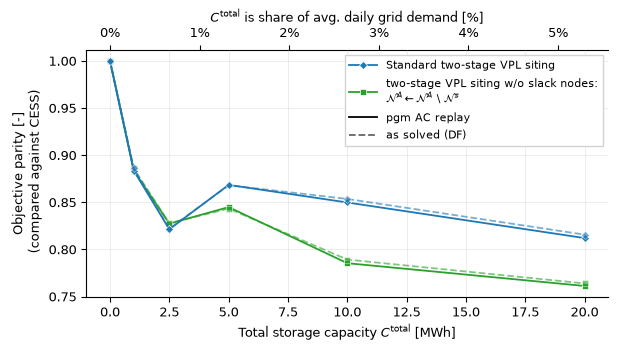

02_parity_VPL_no_slack_C0-S0_both_total

,series,VPL at VPL,VPL w/o slack,VPL at VPL,VPL w/o slack
,objective,pgm AC replay,pgm AC replay,as solved (DF),as solved (DF)
C_total [MWh],C_total [% of avg daily demand],,,,
0.0,0.000000,1.000000,1.000000,1.000000,1.000000
1.0,0.264762,0.883716,0.883716,0.886015,0.886015
2.5,0.661906,0.821443,0.827414,0.821972,0.827913
5.0,1.323811,0.868520,0.844963,0.868143,0.843355
10.0,2.647623,0.849869,0.785461,0.853621,0.789294
20.0,5.295245,0.812114,0.761299,0.815767,0.764015


In [8]:
# (1) VPL siting with / without the slack nodes
for grids in GRIDS:
    parity_plot(slim, grids, series=("VPL at VPL", "VPL w/o slack"), name="02_parity_VPL_no_slack")

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


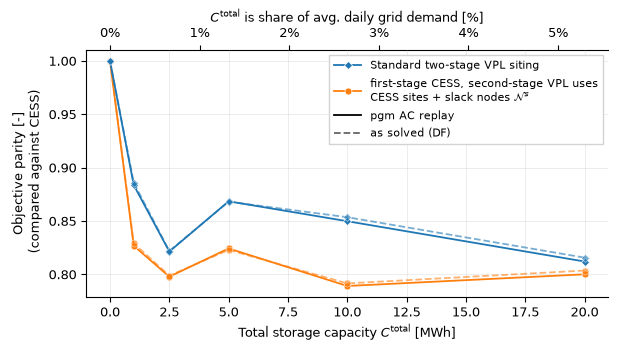

02_parity_VPL_at_CESS_C0-S0_both_total

,series,VPL at VPL,VPL at CESS+slack,VPL at VPL,VPL at CESS+slack
,objective,pgm AC replay,pgm AC replay,as solved (DF),as solved (DF)
C_total [MWh],C_total [% of avg daily demand],,,,
0.0,0.000000,1.000000,1.000000,1.000000,1.000000
1.0,0.264762,0.883716,0.826853,0.886015,0.829212
2.5,0.661906,0.821443,0.797897,0.821972,0.798872
5.0,1.323811,0.868520,0.824359,0.868143,0.822979
10.0,2.647623,0.849869,0.789208,0.853621,0.791609
20.0,5.295245,0.812114,0.800123,0.815767,0.803669


In [9]:
# (2) VPL placed at CESS sites (+slack) vs at VPL sites
for grids in GRIDS:
    parity_plot(slim, grids, series=("VPL at VPL", "VPL at CESS+slack"), name="02_parity_VPL_at_CESS")